# UTS MODUL PRAKTIKUM 1 BIG DATA
## Pemrosesan Terdistribusi PySpark RDD di Google Colab

Nama: Isnaini Nur Hasanah

NIM: 52240005

Prodi: Sains Data 2024

Mata Kuliah: Pemrograman Untuk Big Data

## 1. Instalasi Library & Pengambilan Dataset via `ucimlrepo`

In [ ]:
!pip install -q pyspark ucimlrepo

Dataset diambil langsung dari UCI memakai `fetch_ucirepo(id=352)`. Kolom `InvoiceNo` dan `StockCode` berperan sebagai **ID**, sehingga tidak ikut di `data.features`; karena itu `ids` dan `features` digabung dulu menjadi satu tabel utuh (8 kolom), lalu disimpan sebagai CSV di `/content` (disk cloud Colab) untuk dibaca Spark.

| Kolom | Keterangan |
|---|---|
| InvoiceNo | Nomor transaksi 6 digit; diawali huruf `C` berarti pembatalan |
| StockCode | Kode produk 5 digit |
| Description | Nama produk |
| Quantity | Jumlah item per transaksi |
| InvoiceDate | Tanggal & jam transaksi |
| UnitPrice | Harga per unit (GBP / sterling) |
| CustomerID | ID pelanggan 5 digit |
| Country | Negara pelanggan |

In [ ]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

CSV_PATH = "/content/online_retail.csv"

# fetch dataset
print("Mengambil dataset dari UCI (id=352) ...")
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
ids = online_retail.data.ids          # InvoiceNo, StockCode
X   = online_retail.data.features     # Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country

# variable information
print(online_retail.variables)

# Gabungkan ID + fitur menjadi satu tabel utuh
kolom = ["InvoiceNo", "StockCode", "Description", "Quantity",
         "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
pdf = pd.concat([ids, X], axis=1)[kolom]

# Rapikan tipe data sebelum disimpan sebagai CSV
pdf["InvoiceNo"]   = pdf["InvoiceNo"].astype(str)
pdf["StockCode"]   = pdf["StockCode"].astype(str)
pdf["CustomerID"]  = pd.to_numeric(pdf["CustomerID"], errors="coerce").astype("Int64")   # 17850.0 -> 17850
pdf["InvoiceDate"] = pd.to_datetime(pdf["InvoiceDate"]).dt.strftime("%m/%d/%Y %H:%M")    # MM/DD/YYYY HH:MM
pdf.to_csv(CSV_PATH, index=False)

print(f"\nSelesai. Jumlah baris mentah: {len(pdf):,}  ->  disimpan di {CSV_PATH}")
print("Jumlah CustomerID kosong     :", f"{pdf['CustomerID'].isna().sum():,}")
del pdf

Mengambil dataset dari UCI (id=352) ...
          name     role         type demographic  \
0    InvoiceNo       ID  Categorical        None   
1    StockCode       ID  Categorical        None   
2  Description  Feature  Categorical        None   
3     Quantity  Feature      Integer        None   
4  InvoiceDate  Feature         Date        None   
5    UnitPrice  Feature   Continuous        None   
6   CustomerID  Feature  Categorical        None   
7      Country  Feature  Categorical        None   

                                         description     units missing_values  
0  a 6-digit integral number uniquely assigned to...      None             no  
1  a 5-digit integral number uniquely assigned to...      None             no  
2                                       product name      None             no  
3  the quantities of each product (item) per tran...      None             no  
4  the day and time when each transaction was gen...      None             no  
5          

## 2. Inisialisasi & Verifikasi SparkContext

In [ ]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master("local[*]")
         .appName("PraktikumPySparkRDD")
         .config("spark.driver.memory", "4g")
         .getOrCreate())
sc = spark.sparkContext

print("--- INFORMASI CLUSTER SPARK (COLAB) ---")
print(f"Versi PySpark       : {spark.version}")
print(f"Master Node         : {sc.master}")
print(f"Default Parallelism : {sc.defaultParallelism} (jumlah core CPU yang tersedia)")

--- INFORMASI CLUSTER SPARK (COLAB) ---
Versi PySpark       : 4.0.5
Master Node         : local[*]
Default Parallelism : 2 (jumlah core CPU yang tersedia)


## 3. Membaca Dataset ke PySpark RDD

In [ ]:
file_path = CSV_PATH

df_raw = (spark.read.format("csv")
          .option("header", "true")
          .option("inferSchema", "true")
          .option("multiLine", "true")
          .option("escape", '"')
          .load(file_path))

# Pembersihan data awal: hapus baris dengan nilai NULL pada kolom vital
df_clean = df_raw.dropna(subset=["InvoiceNo", "CustomerID", "UnitPrice", "Quantity"])

# Konversi DataFrame ke RDD Tuple
# Format Tuple: (InvoiceNo, StockCode, Description, Quantity, UnitPrice, CustomerID, Country)
rdd_raw = df_clean.rdd.map(lambda row: (
    str(row['InvoiceNo']),
    str(row['StockCode']),
    str(row['Description']),
    int(row['Quantity']),
    float(row['UnitPrice']),
    str(row['CustomerID']),
    str(row['Country'])
))

# Optimasi partisi data terdistribusi
rdd = rdd_raw.repartition(8)

# RDD pendukung khusus untuk Tugas C1 (butuh kolom InvoiceDate yang tidak ada di tuple utama)
# Format Tuple: (InvoiceDate, Quantity, UnitPrice)
rdd_waktu = df_clean.rdd.map(lambda row: (
    str(row['InvoiceDate']),
    int(row['Quantity']),
    float(row['UnitPrice'])
))

print(f"Jumlah Total Record Terbersih: {rdd.count():,}")
print("\nContoh 3 Transaksi Pertama:")
for row in rdd.take(3):
    print(row)

Jumlah Total Record Terbersih: 406,829

Contoh 3 Transaksi Pertama:
('536373', '82494L', 'WOODEN FRAME ANTIQUE WHITE ', 6, 2.55, '17850', 'United Kingdom')
('536373', '84029G', 'KNITTED UNION FLAG HOT WATER BOTTLE', 6, 3.39, '17850', 'United Kingdom')
('536373', '84029E', 'RED WOOLLY HOTTIE WHITE HEART.', 6, 3.39, '17850', 'United Kingdom')


## 4. Transformasi RDD (`filter` & `map`)

In [ ]:
# Filter transaksi valid: Quantity > 0, UnitPrice > 0, dan berasal dari 'United Kingdom'
rdd_uk_valid = rdd.filter(lambda x: x[3] > 0 and x[4] > 0 and x[6] == 'United Kingdom')

# Transformasi map untuk membentuk Tuple Key-Value: (InvoiceNo, TotalSpent)
rdd_invoice_spent = rdd_uk_valid.map(lambda x: (x[0], round(x[3] * x[4], 2)))

print(f"Jumlah Transaksi Valid UK: {rdd_uk_valid.count():,}")
print("Contoh Pair RDD (InvoiceNo, TotalSpent):", rdd_invoice_spent.take(3))

Jumlah Transaksi Valid UK: 354,321
Contoh Pair RDD (InvoiceNo, TotalSpent): [('536373', 15.3), ('536373', 20.34), ('536373', 20.34)]


## 5. Agregasi RDD (`reduceByKey` & Sorting)

In [ ]:
import time

start_time = time.time()

rdd_total_per_invoice = rdd_invoice_spent.reduceByKey(lambda a, b: a + b)
rdd_sorted_invoice = rdd_total_per_invoice.sortBy(lambda x: x[1], ascending=False)

top_10_invoices = rdd_sorted_invoice.take(10)
execution_time = time.time() - start_time

print(f"Waktu Eksekusi Agregasi RDD: {execution_time:.4f} detik\n")
print("--- TOP 10 INVOICE DENGAN TRANSAKSI TERBESAR ---")
for invoice, total in top_10_invoices:
    print(f"Invoice ID: {invoice:<10} | Total Belanja: £ {total:,.2f}")

Waktu Eksekusi Agregasi RDD: 6.2538 detik

--- TOP 10 INVOICE DENGAN TRANSAKSI TERBESAR ---
Invoice ID: 581483     | Total Belanja: £ 168,469.60
Invoice ID: 541431     | Total Belanja: £ 77,183.60
Invoice ID: 556444     | Total Belanja: £ 38,970.00
Invoice ID: 567423     | Total Belanja: £ 31,698.16
Invoice ID: 572209     | Total Belanja: £ 22,206.00
Invoice ID: 567381     | Total Belanja: £ 22,104.80
Invoice ID: 550461     | Total Belanja: £ 21,535.90
Invoice ID: 562439     | Total Belanja: £ 18,841.48
Invoice ID: 556255     | Total Belanja: £ 16,488.00
Invoice ID: 537659     | Total Belanja: £ 15,885.49


## 6. Optimasi RDD: Caching & Persistence

In [ ]:
from pyspark import StorageLevel

rdd_sorted_invoice.persist(StorageLevel.MEMORY_ONLY)

# Aksi pertama (cache warmup)
t0 = time.time()
count_1 = rdd_sorted_invoice.count()
t1 = time.time() - t0

# Aksi kedua (membaca langsung dari RAM)
t2 = time.time()
count_2 = rdd_sorted_invoice.count()
t3 = time.time() - t2

print(f"Eksekusi Aksi Pertama (Tanpa Cache Warmup) : {t1:.4f} detik")
print(f"Eksekusi Aksi Kedua (Menggunakan Cache)     : {t3:.4f} detik")

rdd_sorted_invoice.unpersist()

Eksekusi Aksi Pertama (Tanpa Cache Warmup) : 1.2477 detik
Eksekusi Aksi Kedua (Menggunakan Cache)     : 0.7331 detik


PythonRDD[30] at RDD at PythonRDD.scala:57

## 7. Analisis Produk Paling Laris

In [ ]:
rdd_product_qty = (rdd_uk_valid.map(lambda x: (x[2], x[3]))
                               .reduceByKey(lambda a, b: a + b)
                               .sortBy(lambda x: x[1], ascending=False))

print("--- TOP 5 PRODUK TERLARIS ---")
for product, total_qty in rdd_product_qty.take(5):
    print(f"Produk: {product:<40} | Jumlah Terjual: {total_qty:,} unit")

--- TOP 5 PRODUK TERLARIS ---
Produk: PAPER CRAFT , LITTLE BIRDIE              | Jumlah Terjual: 80,995 unit
Produk: MEDIUM CERAMIC TOP STORAGE JAR           | Jumlah Terjual: 76,919 unit
Produk: WORLD WAR 2 GLIDERS ASSTD DESIGNS        | Jumlah Terjual: 49,182 unit
Produk: JUMBO BAG RED RETROSPOT                  | Jumlah Terjual: 41,981 unit
Produk: WHITE HANGING HEART T-LIGHT HOLDER       | Jumlah Terjual: 34,648 unit


## 8. Tugas Mandiri Mahasiswa


### KATEGORI A: Analisis Data & Eksplorasi Bisnis

#### Tugas A1: Top 5 Pelanggan Luar UK (Non-UK)


In [ ]:
# 1. Filter transaksi non-UK (pembelian valid)
rdd_non_uk = rdd.filter(lambda x: x[6] != 'United Kingdom' and x[3] > 0 and x[4] > 0)

# 2. Pair RDD: (CustomerID, TotalSpent)
rdd_cust_spent = rdd_non_uk.map(lambda x: (x[5], x[3] * x[4]))

# 3. Total belanja per CustomerID, lalu Top 5
rdd_cust_total = rdd_cust_spent.reduceByKey(lambda a, b: a + b)
top5_cust = rdd_cust_total.sortBy(lambda x: x[1], ascending=False).take(5)

print(f"Jumlah record non-UK valid: {rdd_non_uk.count():,}")
print("\n--- TOP 5 PELANGGAN NON-UK DENGAN PENGELUARAN TERBESAR ---")
for i, (cust, total) in enumerate(top5_cust, 1):
    print(f"{i}. CustomerID: {cust:<8} | Total Belanja: £ {total:,.2f}")

Jumlah record non-UK valid: 43,563

--- TOP 5 PELANGGAN NON-UK DENGAN PENGELUARAN TERBESAR ---
1. CustomerID: 14646    | Total Belanja: £ 280,206.02
2. CustomerID: 14911    | Total Belanja: £ 143,825.06
3. CustomerID: 12415    | Total Belanja: £ 124,914.53
4. CustomerID: 14156    | Total Belanja: £ 117,379.63
5. CustomerID: 17404    | Total Belanja: £ 31,906.82


Dari 43.563 record pembelian valid di luar UK, pengeluaran terbesar berasal dari CustomerID 14646 sebesar £280.206,02. Nilai ini hampir dua kali lipat pelanggan peringkat kedua (£143.825,06). Setelah peringkat 4 (£117.379,63), nilainya turun tajam: pelanggan peringkat 5 hanya £31.906,82, sekitar seperempat dari peringkat 4. Artinya pendapatan dari pasar luar negeri sangat terkonsentrasi pada segelintir pelanggan besar, bukan menyebar merata. Pola ini sesuai deskripsi dataset UCI bahwa banyak pelanggan toko ini adalah grosir. Dari sisi bisnis, kehilangan satu atau dua pelanggan teratas akan berdampak besar pada pendapatan ekspor, jadi mereka layak mendapat perhatian khusus (misalnya program loyalitas atau akun manajer).

#### Tugas A2: Potensi Kerugian Transaksi Pembatalan/Retur


In [ ]:
# 1. Filter transaksi pembatalan/retur (dari seluruh data bersih, semua negara)
rdd_batal = rdd.filter(lambda x: x[0].startswith('C') or x[3] < 0)

# 2. Jumlah transaksi yang dibatalkan
jumlah_baris_batal   = rdd_batal.count()
jumlah_invoice_batal = rdd_batal.map(lambda x: x[0]).distinct().count()

# 3. Total estimasi nilai kerugian (GBP)
total_kerugian = rdd_batal.map(lambda x: abs(x[3] * x[4])).sum()

print(f"Jumlah baris transaksi dibatalkan  : {jumlah_baris_batal:,}")
print(f"Jumlah invoice pembatalan (unik)   : {jumlah_invoice_batal:,}")
print(f"Total estimasi nilai kerugian      : £ {total_kerugian:,.2f}")

Jumlah baris transaksi dibatalkan  : 8,905
Jumlah invoice pembatalan (unik)   : 3,654
Total estimasi nilai kerugian      : £ 611,342.09


Ada 8.905 baris transaksi pembatalan yang tersebar di 3.654 invoice unik, dengan estimasi nilai £611.342,09. Satu invoice pembatalan rata-rata berisi sekitar 2,4 baris produk dan bernilai sekitar £167. Angka ini adalah nilai kotor barang yang dibatalkan atau diretur, bukan kerugian bersih. Penjualan aslinya tercatat terpisah, dan sebagian retur mungkin sudah diganti atau dijual kembali. Karena kriteria memakai “atau” (C atau Quantity < 0), baris dengan Quantity negatif tanpa awalan C (misalnya koreksi stok) juga ikut terhitung, sehingga angka ini bisa sedikit melebihi retur murni. Angka ini tetap berguna sebagai indikator besarnya biaya pembatalan yang perlu ditekan, misalnya lewat perbaikan deskripsi produk atau kontrol kualitas.

### KATEGORI B: Optimasi Performa & Benchmark RDD

#### Tugas B1: Pengaruh Jumlah Partisi terhadap Waktu Eksekusi


Partisi = 2   | jumlah key = 3,920 | rata-rata waktu = 2.0991 detik | tiap run = [1.998, 2.268, 2.032]
Partisi = 8   | jumlah key = 3,920 | rata-rata waktu = 3.1236 detik | tiap run = [4.325, 2.482, 2.564]
Partisi = 16  | jumlah key = 3,920 | rata-rata waktu = 3.9209 detik | tiap run = [3.164, 4.125, 4.473]


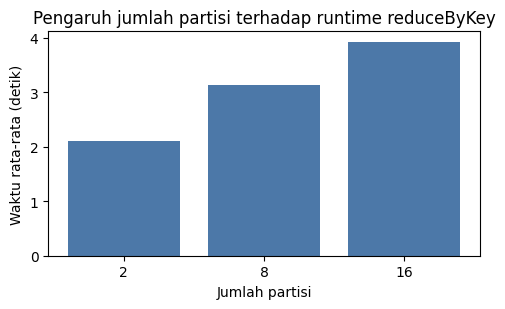

In [ ]:
import matplotlib.pyplot as plt

pair_cust = rdd_uk_valid.map(lambda x: (x[5], x[3] * x[4]))
pair_cust.count()   # warm-up (JIT/JVM) agar run pertama tidak menjadi outlier

variasi_partisi = [2, 8, 16]
ulangan = 3
hasil_b1 = {}

for n in variasi_partisi:
    waktu = []
    for _ in range(ulangan):
        t = time.time()
        hasil = pair_cust.repartition(n).reduceByKey(lambda a, b: a + b).count()
        waktu.append(time.time() - t)
    hasil_b1[n] = sum(waktu) / len(waktu)
    print(f"Partisi = {n:<3} | jumlah key = {hasil:,} | "
          f"rata-rata waktu = {hasil_b1[n]:.4f} detik | tiap run = {[round(w, 3) for w in waktu]}")

plt.figure(figsize=(5, 3.2))
plt.bar([str(n) for n in hasil_b1], list(hasil_b1.values()), color="#4C78A8")
plt.xlabel("Jumlah partisi"); plt.ylabel("Waktu rata-rata (detik)")
plt.title("Pengaruh jumlah partisi terhadap runtime reduceByKey")
plt.tight_layout(); plt.show()

Waktu rata-rata justru naik seiring bertambahnya partisi: 2,10 detik (2 partisi), 3,12 detik (8 partisi), dan 3,92 detik (16 partisi), seperti terlihat pada grafik. Penyebabnya, Colab berjalan di mode lokal dengan sangat sedikit core CPU, jadi tambahan partisi tidak menambah paralelisme nyata. Yang bertambah hanya overhead: repartition memicu shuffle penuh, lalu setiap partisi menjadi task tersendiri yang harus dijadwalkan, dan hasil akhirnya hanya 3.920 key sehingga pekerjaan per partisi sangat kecil. Run pertama pada 8 partisi (4,325 detik) tampak sebagai outlier, kemungkinan karena proses awal JVM atau garbage collection, tetapi dua run lainnya (sekitar 2,5 detik) tetap lebih lambat dari 2 partisi, sehingga kesimpulannya tidak berubah. Jadi jumlah partisi sebaiknya disesuaikan dengan jumlah core dan ukuran data. Pada cluster besar dengan data berukuran GB sampai TB, partisi yang lebih banyak (sekitar 2–4 kali jumlah core) barulah memberi keuntungan.

#### Tugas B2: `reduceByKey` vs `groupByKey`


In [ ]:
pair_prod = rdd_uk_valid.map(lambda x: (x[2], x[3])).cache()
pair_prod.count()   # materialisasi cache

def ukur(fungsi, ulangan=3):
    waktu = []
    for _ in range(ulangan):
        t = time.time()
        fungsi()
        waktu.append(time.time() - t)
    return sum(waktu) / len(waktu), waktu

rata_reduce, runs_reduce = ukur(lambda: pair_prod.reduceByKey(lambda a, b: a + b).count())
rata_group,  runs_group  = ukur(lambda: pair_prod.groupByKey().mapValues(sum).count())

# Verifikasi kedua metode menghasilkan hasil yang sama
hasil_reduce = dict(pair_prod.reduceByKey(lambda a, b: a + b).collect())
hasil_group  = dict(pair_prod.groupByKey().mapValues(sum).collect())
print("Hasil kedua metode identik:", hasil_reduce == hasil_group)

print(f"\nreduceByKey                : {rata_reduce:.4f} detik (rata-rata) | {[round(w, 3) for w in runs_reduce]}")
print(f"groupByKey + mapValues(sum): {rata_group:.4f} detik (rata-rata) | {[round(w, 3) for w in runs_group]}")

selisih = rata_group - rata_reduce
if selisih > 0:
    print(f"\nreduceByKey lebih cepat {selisih:.4f} detik (~{rata_group / rata_reduce:.2f}x)")
else:
    print(f"\ngroupByKey lebih cepat {-selisih:.4f} detik pada data/cluster ini")

pair_prod.unpersist()

Hasil kedua metode identik: True

reduceByKey                : 1.0702 detik (rata-rata) | [0.877, 1.097, 1.237]
groupByKey + mapValues(sum): 0.8689 detik (rata-rata) | [0.884, 0.91, 0.812]

groupByKey lebih cepat 0.2014 detik pada data/cluster ini


PythonRDD[154] at RDD at PythonRDD.scala:57

Hasil kedua metode identik, tetapi groupByKey + mapValues(sum) justru tercatat lebih cepat (0,869 detik) dibanding reduceByKey (1,070 detik), selisih 0,20 detik. Ini tidak otomatis membuktikan groupByKey lebih baik. Pada run pertama waktu keduanya hampir sama (0,877 vs 0,884 detik), dan run reduceByKey berfluktuasi (0,877–1,237 detik) sehingga rentangnya tumpang tindih dengan groupByKey, jadi selisihnya masih dalam batas noise. Secara teori reduceByKey unggul karena menggabungkan nilai di sisi map sebelum shuffle, sehingga data yang dikirim jauh lebih sedikit, sedangkan groupByKey mengirim semua pasangan key-value dan menampung seluruh nilai satu key di memori. Pada mode lokal satu mesin tidak ada transfer data antar-node dan datanya kecil, sehingga keunggulan itu hampir tidak terlihat. Pada cluster nyata dengan data besar, reduceByKey tetap pilihan yang lebih efisien dan aman dari risiko kehabisan memori. Baris PythonRDD[154] at RDD at PythonRDD.scala:57 di akhir output hanya nilai kembalian unpersist() yang ikut tercetak, bukan error.

### KATEGORI C: Pemrosesan String & Waktu

#### Tugas C1: Jam Sibuk Transaksi


In [ ]:
import re
from operator import add

def ambil_jam(teks):
    # Mengambil bagian jam dari "12/01/2010 08:26" (juga aman untuk format "2010-12-01 08:26:00")
    m = re.search(r'(\d{1,2}):\d{2}', teks)
    return int(m.group(1)) if m else None

rdd_jam = (rdd_waktu.filter(lambda x: x[1] > 0 and x[2] > 0)
                    .map(lambda x: (ambil_jam(x[0]), 1))
                    .filter(lambda x: x[0] is not None)
                    .reduceByKey(add))

top3_jam = rdd_jam.sortBy(lambda x: x[1], ascending=False).take(3)

print("--- TOP 3 JAM TERSIBUK ---")
for i, (jam, frek) in enumerate(top3_jam, 1):
    print(f"{i}. Jam {jam:02d}:00 - {jam:02d}:59 | {frek:,} baris transaksi")

print("\n--- DISTRIBUSI SELURUH JAM ---")
for jam, frek in rdd_jam.sortByKey().collect():
    print(f"Jam {jam:02d} | {frek:>7,} | {'█' * int(frek / max(1, top3_jam[0][1]) * 40)}")

--- TOP 3 JAM TERSIBUK ---
1. Jam 12:00 - 12:59 | 72,065 baris transaksi
2. Jam 13:00 - 13:59 | 64,026 baris transaksi
3. Jam 14:00 - 14:59 | 54,118 baris transaksi

--- DISTRIBUSI SELURUH JAM ---
Jam 06 |       1 | 
Jam 07 |     379 | 
Jam 08 |   8,690 | ████
Jam 09 |  21,944 | ████████████
Jam 10 |  37,997 | █████████████████████
Jam 11 |  49,084 | ███████████████████████████
Jam 12 |  72,065 | ████████████████████████████████████████
Jam 13 |  64,026 | ███████████████████████████████████
Jam 14 |  54,118 | ██████████████████████████████
Jam 15 |  45,369 | █████████████████████████
Jam 16 |  24,089 | █████████████
Jam 17 |  13,071 | ███████
Jam 18 |   2,928 | █
Jam 19 |   3,321 | █
Jam 20 |     802 | 


Aktivitas transaksi memuncak pada pukul 12:00–12:59 (72.065 baris), diikuti pukul 13:00 (64.026) dan 14:00 (54.118). Tiga jam ini menyumbang sekitar 48% dari seluruh 397.884 baris transaksi, dan pukul 12 saja sekitar 18%. Distribusinya berbentuk lonceng: transaksi mulai naik pukul 08:00, memuncak saat tengah hari, lalu menurun sore hari dan hampir nol sebelum pukul 07:00 dan setelah pukul 20:00. Pola ini menunjukkan pelanggan banyak berbelanja pada jam kerja dan jam makan siang. Secara operasional, kapasitas server, stok, dan tim layanan pelanggan sebaiknya diprioritaskan pada rentang 11:00–15:00, sedangkan pekerjaan berat (batch, pemeliharaan sistem) dijadwalkan di luar jam tersebut. Perlu diingat bahwa yang dihitung adalah baris item, bukan jumlah invoice, sehingga jam dengan keranjang belanja besar akan tampak lebih sibuk.

#### Tugas C2: Rata-rata Harga Produk Berkata Kunci "HEART"


In [ ]:
# 1. Filter produk yang deskripsinya mengandung "HEART" (case-insensitive)
rdd_heart = rdd_uk_valid.filter(lambda x: 'HEART' in x[2].upper())

# 2. Rata-rata harga per varian: (Description, (sum_harga, jumlah)) -> sum / jumlah
rdd_heart_avg = (rdd_heart.map(lambda x: (x[2], (x[4], 1)))
                          .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                          .mapValues(lambda v: round(v[0] / v[1], 2)))

# 3. Total varian dan 5 contoh
total_varian = rdd_heart_avg.count()
print(f"Total varian produk mengandung 'HEART': {total_varian:,}\n")
print("--- CONTOH 5 PRODUK (urut abjad) ---")
for produk, rata in rdd_heart_avg.sortBy(lambda x: x[0]).take(5):
    print(f"Produk: {produk:<42} | Rata-rata Harga: £ {rata:,.2f}")

Total varian produk mengandung 'HEART': 297

--- CONTOH 5 PRODUK (urut abjad) ---
Produk: 3 BLACK CATS W HEARTS BLANK CARD           | Rata-rata Harga: £ 0.19
Produk: 3 HEARTS HANGING DECORATION RUSTIC         | Rata-rata Harga: £ 2.98
Produk: 3 TIER SWEETHEART GARDEN SHELF             | Rata-rata Harga: £ 35.65
Produk: 36 FOIL HEART CAKE CASES                   | Rata-rata Harga: £ 2.04
Produk: 3D HEARTS  HONEYCOMB PAPER GARLAND         | Rata-rata Harga: £ 2.94


Ditemukan 297 varian produk yang deskripsinya mengandung “HEART”, dengan rata-rata harga yang sangat beragam, dari £0,19 (kartu ucapan) hingga £35,65 (rak taman). Rentang ini menunjukkan “HEART” hanyalah motif desain yang dipakai di banyak jenis barang, bukan satu kategori produk dengan harga seragam. Karena pencocokan memakai substring, kata seperti “HEARTS” dan “SWEETHEART” ikut terambil. Rata-rata yang dihitung adalah rata-rata sederhana harga per baris transaksi untuk tiap varian, tanpa pembobotan jumlah terjual.

### KATEGORI D: Operasi Multiset & Set Operations

#### Tugas D1: Eksklusivitas Pasar Germany vs France (`subtract`)


In [ ]:
# 1 & 2. Nama produk unik per negara
produk_germany = rdd.filter(lambda x: x[6] == 'Germany' and x[3] > 0).map(lambda x: x[2]).distinct()
produk_france  = rdd.filter(lambda x: x[6] == 'France'  and x[3] > 0).map(lambda x: x[2]).distinct()

# 3. Produk di Germany TETAPI tidak pernah di France
produk_eksklusif = produk_germany.subtract(produk_france)

# 4. Hasil
print(f"Produk unik Germany : {produk_germany.count():,}")
print(f"Produk unik France  : {produk_france.count():,}")
print(f"Produk eksklusif Germany (tidak pernah dibeli di France): {produk_eksklusif.count():,}")
print("\n--- CONTOH 5 PRODUK EKSKLUSIF (urut abjad) ---")
for p in produk_eksklusif.sortBy(lambda x: x).take(5):
    print("-", p)

Produk unik Germany : 1,697
Produk unik France  : 1,544
Produk eksklusif Germany (tidak pernah dibeli di France): 514

--- CONTOH 5 PRODUK EKSKLUSIF (urut abjad) ---
-  RED SPOT GIFT BAG LARGE
- 12 IVORY ROSE PEG PLACE SETTINGS
- 12 PENCILS TALL TUBE SKULLS
- 12 PINK HEN+CHICKS IN BASKET
- 12 RED ROSE PEG PLACE SETTINGS


Germany memiliki 1.697 produk unik dan France 1.544. Sebanyak 514 produk (sekitar 30% dari produk Germany) tidak pernah dibeli di France, sedangkan sisanya, sekitar 1.183 produk (70%), juga dibeli di France. Jadi kedua pasar sangat tumpang tindih, dan perbedaan selera di antara keduanya relatif kecil. Hasil subtract() bersifat searah: produk yang ada di France tetapi tidak di Germany belum terhitung (sekitar 361 produk bila dihitung dari selisihnya). Jumlah eksklusif ini juga dipengaruhi ukuran sampel, karena Germany punya lebih banyak produk terbeli sehingga peluang ada produk yang “tidak muncul” di France lebih besar. Ada juga isu kualitas data: contoh pertama (RED SPOT GIFT BAG LARGE) diawali spasi, jadi bisa dianggap berbeda dari penulisan tanpa spasi. Menambahkan .strip() sebelum distinct() kemungkinan akan sedikit menurunkan angka 514.

In [ ]:
spark.stop()